# Week 5 - Red Agent, Part 2 (FGSM + PGD with ART)

Builds the 4 sample categories: **genuine, GAN-generated, FGSM-attacked, PGD-attacked**.

Needs from earlier weeks (all inside `celeba/`): `preprocessed_v2/`, `train_split.csv`, `generator_dcgan.pth`.

Attack target: FaceNet (InceptionResnetV1, vggface2, frozen) + a small linear identity head. ART attacks need a classifier loss, so the head turns the 512-d embedding into identity logits.

**Update (Oct 2026) - Blue Agent dataset version:**

| setting | before | now | why |
|---|---|---|---|
| GAN generator | `generator_dcgan.pth` (25 epochs) | **`generator_dcgan_50ep.pth` (50 epochs)** | final, better DCGAN |
| identities (`N_ID`) | 100 | **300** | each identity only has 5 images (3 enrolled + 2 held out), so 500 genuine samples need ~250+ identities |
| images per category (`N_ATTACK`) | 64 | **500** | 64 is far too few to train the Blue Agent CNN |
| working directory | teammate's Windows path | **`/workspace`** (RunPod) | runs on the pod's GPU |
| ART install | automatic `pip install` inside the notebook | installed once on the pod beforehand | the pod's Python blocks in-notebook installs |

the attack itself is unchanged (same FaceNet target, same `eps = 8/255`, same FGSM/PGD settings). because the identity head now has 300 classes instead of 100, the numbers in `results.csv` are not directly comparable to the old 64-sample run - they are the ones to report from now on.

**Update 2 (Oct 2026) - 5th category, as required by the GP documentation (sections 1.4.2 / 1.4.3, FR 2.2):** *combined GAN-based adversarial samples* (`gan_adv`): 500 **new** GAN faces (not the same faces as the `gan` category, so no base face appears in two categories), 250 attacked with FGSM and 250 with PGD, same `eps` and settings. `labels.csv` has a new `attack` column (`none`, `fgsm`, `pgd`) saying which attack produced each image. The four existing categories are generated exactly as before (same seed); the new section uses its own seed, so it does not change them.


In [1]:
import os, sys, subprocess, time
os.chdir("/workspace")
print("working directory:", os.getcwd())

try:
    import art
except ImportError:
    raise ImportError("ART is not installed on this machine - install it on the pod first: "
                      "pip install --break-system-packages adversarial-robustness-toolbox")
print("ART version:", art.__version__)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from facenet_pytorch import InceptionResnetV1
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

working directory: /workspace
ART version: 1.20.1
device: cuda


In [2]:
BASE = "./celeba"
IMG_DIR = os.path.join(BASE, "preprocessed_v2")
OUT_DIR = os.path.join(BASE, "red_agent_samples")

# generator weights: accepts either location
GEN_PATH = next((p for p in [
    os.path.join(BASE, "generator_dcgan_50ep.pth"),      # final 50-epoch DCGAN (preferred)
    os.path.join(BASE, "generator_dcgan.pth"),
    os.path.join(BASE, "002 generator_dcgan.pth", "generator_dcgan.pth"),
] if os.path.exists(p)), None)
assert GEN_PATH, "generator_dcgan_50ep.pth not found inside celeba/ - upload it first"

N_ID = 300           # identities used for the classifier head (was 100)
N_ATTACK = 500       # images per category (was 64) - Blue Agent training set size
N_GAN_ADV = 500      # combined GAN + adversarial samples: half FGSM, half PGD (5th category)
EPS = 2 * 8 / 255    # 8/255 in pixel space = 0.0627 in the [-1, 1] range
BATCH = 16
print("generator:", GEN_PATH)

generator: ./celeba/generator_dcgan_50ep.pth


### 1. data
300 identities from `train_split.csv` (5 images each): 3 images are "enrolled" (train the head), 2 are held out and used as the genuine samples -> 900 enrolled, 600 held out, of which up to 500 (those the model already gets right) are used.

In [3]:
train_df = pd.read_csv(os.path.join(BASE, "train_split.csv"))
counts = train_df["identity"].value_counts()
eligible = counts[counts >= 5].index.to_numpy()
ids = np.random.choice(eligible, N_ID, replace=False)
id_to_idx = {int(i): k for k, i in enumerate(ids)}
idx_to_id = {k: i for i, k in id_to_idx.items()}

def load_img(fname):
    img = Image.open(os.path.join(IMG_DIR, fname)).convert("RGB")
    a = np.asarray(img, dtype=np.float32) / 255.0
    return ((a - 0.5) / 0.5).transpose(2, 0, 1)      # CHW, range [-1, 1]

tr_files, tr_y, ev_files, ev_y = [], [], [], []
for i in ids:
    files = train_df.loc[train_df["identity"] == i, "file_name"].tolist()[:5]
    tr_files += files[:3]; tr_y += [id_to_idx[int(i)]] * 3
    ev_files += files[3:5]; ev_y += [id_to_idx[int(i)]] * 2

x_tr = np.stack([load_img(f) for f in tr_files]); y_tr = np.array(tr_y)
x_ev = np.stack([load_img(f) for f in ev_files]); y_ev = np.array(ev_y)
print("enrolled:", x_tr.shape, "| held-out genuine:", x_ev.shape)

enrolled: (900, 3, 160, 160) | held-out genuine: (600, 3, 160, 160)


### 2. face recognition model
Frozen FaceNet + linear identity head trained on the embeddings.

In [4]:
backbone = InceptionResnetV1(pretrained="vggface2").eval().to(device)
for p in backbone.parameters():
    p.requires_grad = False

@torch.no_grad()
def embed(x, bs=64):
    out = []
    for i in range(0, len(x), bs):
        out.append(backbone(torch.from_numpy(x[i:i + bs]).to(device)).cpu())
    return torch.cat(out)                            # [N, 512], L2-normalized

emb_tr, emb_ev = embed(x_tr), embed(x_ev)

head = nn.Linear(512, N_ID).to(device)
opt = torch.optim.Adam(head.parameters(), lr=0.05)
Et, yt = emb_tr.to(device), torch.from_numpy(y_tr).to(device)
for step in range(500):
    opt.zero_grad()
    F.cross_entropy(head(Et), yt).backward()
    opt.step()

with torch.no_grad():
    acc_tr = (head(Et).argmax(1).cpu().numpy() == y_tr).mean()
    acc_ev = (head(emb_ev.to(device)).argmax(1).cpu().numpy() == y_ev).mean()
print(f"head train acc: {acc_tr:.1%} | held-out genuine acc: {acc_ev:.1%}")

  0%|          | 0.00/107M [00:00<?, ?B/s]

head train acc: 100.0% | held-out genuine acc: 92.8%


In [5]:
class FaceClassifier(nn.Module):
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone, self.head = backbone, head
    def forward(self, x):
        return self.head(self.backbone(x))

model = FaceClassifier(backbone, head).eval().to(device)

classifier = PyTorchClassifier(
    model=model,
    loss=nn.CrossEntropyLoss(),
    input_shape=(3, 160, 160),
    nb_classes=N_ID,
    clip_values=(-1.0, 1.0),                         # matches Normalize(0.5, 0.5)
    device_type="gpu" if torch.cuda.is_available() else "cpu",
)
print("ART classifier ready")

ART classifier ready


### 3. GAN-generated faces
Generator from Part 1 (64x64, **50 epochs**), upsampled to 160x160 so FaceNet accepts it.

In [6]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100, feature_maps=64):
        super().__init__()
        self.main = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, feature_maps * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(True),
            nn.ConvTranspose2d(feature_maps, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, x):
        return self.main(x)

generator = Generator(100).to(device)
generator.load_state_dict(torch.load(GEN_PATH, map_location=device))
generator.eval()

with torch.no_grad():
    z = torch.randn(N_ATTACK, 100, 1, 1, device=device)
    fake160 = F.interpolate(generator(z), size=160, mode="bilinear", align_corners=False)
x_gan = fake160.clamp(-1, 1).cpu().numpy().astype(np.float32)
print("GAN faces:", x_gan.shape)

GAN faces: (500, 3, 160, 160)


### 4. FGSM and PGD
- **FGSM** (one step): `x_adv = x + eps * sign(grad_x L(x, y))`
- **PGD** (iterative): repeat small FGSM steps, projecting back into the `eps` ball (L-inf) after each one, from a random start.

Only genuine images the model already classifies correctly are attacked, so every flip is caused by the attack.

In [7]:
pred_ev = classifier.predict(x_ev, batch_size=BATCH).argmax(1)
ok = np.where(pred_ev == y_ev)[0]
sel = np.random.choice(ok, min(N_ATTACK, len(ok)), replace=False)
x_gen, y_gen = x_ev[sel], y_ev[sel]
gen_files = [ev_files[i] for i in sel]
y_onehot = np.eye(N_ID, dtype=np.float32)[y_gen]
print("images to attack:", len(x_gen))

fgsm = FastGradientMethod(classifier, eps=EPS, batch_size=BATCH)
pgd = ProjectedGradientDescent(classifier, norm=np.inf, eps=EPS, eps_step=EPS / 8,
                               max_iter=20, num_random_init=1, batch_size=BATCH, verbose=False)

t = time.time()
x_fgsm = fgsm.generate(x=x_gen, y=y_onehot)
x_pgd = pgd.generate(x=x_gen, y=y_onehot)
print(f"attacks done in {time.time() - t:.1f}s")

# images are saved as 8-bit PNG, so evaluate what survives the rounding
def quantize(x):
    return np.round((x * 0.5 + 0.5) * 255).clip(0, 255).astype(np.uint8)

def dequantize(u):
    return (u.astype(np.float32) / 255 - 0.5) / 0.5

x_fgsm_q = dequantize(quantize(x_fgsm))
x_pgd_q = dequantize(quantize(x_pgd))

images to attack: 500
attacks done in 55.8s


### 4b. combined GAN + adversarial samples (5th category)
the GP documentation asks for FGSM and PGD to be applied to GAN-generated faces too ("combined GAN-based adversarial samples").

- **500 new GAN faces** from the same 50-epoch generator, drawn with their own seed (`SEED + 1`), so they are different faces from the `gan` category and the four categories above stay exactly as they were.
- **first 250 -> FGSM, last 250 -> PGD**, with the same `fgsm` / `pgd` attack objects (same `eps = 8/255`, same 20 PGD steps).
- a GAN face belongs to nobody, so the attack needs a reference identity: each face is pushed **away from the identity the model currently matches it to** - untargeted, like the FGSM/PGD on genuine faces.
- each new GAN face is first rounded to 8-bit (the image a saved GAN PNG would hold), then attacked, then rounded to 8-bit PNG again before evaluation - so, like the other attacks, no pixel moves more than 8/255 in the saved file.

In [8]:
g_adv = torch.Generator(device=device).manual_seed(SEED + 1)   # own seed: the four categories above are not affected
with torch.no_grad():
    z2 = torch.randn(N_GAN_ADV, 100, 1, 1, device=device, generator=g_adv)
    fake2 = F.interpolate(generator(z2), size=160, mode="bilinear", align_corners=False)
x_gan2 = fake2.clamp(-1, 1).cpu().numpy().astype(np.float32)    # new GAN faces (clean)
x_gan2 = dequantize(quantize(x_gan2))   # start from the 8-bit image a saved GAN PNG holds, so the attack stays within 8/255 after saving

# reference identity = the person each GAN face currently matches best
y_gan2 = classifier.predict(x_gan2, batch_size=BATCH).argmax(1)
y_gan2_onehot = np.eye(N_ID, dtype=np.float32)[y_gan2]
half = N_GAN_ADV // 2

t = time.time()
x_gan_fgsm = fgsm.generate(x=x_gan2[:half], y=y_gan2_onehot[:half])
x_gan_pgd = pgd.generate(x=x_gan2[half:], y=y_gan2_onehot[half:])
print(f"combined attacks done in {time.time() - t:.1f}s")

x_gan_fgsm_q = dequantize(quantize(x_gan_fgsm))
x_gan_pgd_q = dequantize(quantize(x_gan_pgd))
x_gan_adv_q = np.concatenate([x_gan_fgsm_q, x_gan_pgd_q])
gan_adv_attack = ["fgsm"] * half + ["pgd"] * (N_GAN_ADV - half)
print("combined GAN + adversarial samples:", x_gan_adv_q.shape, "| FGSM:", half, "| PGD:", N_GAN_ADV - half)

combined attacks done in 19.0s
combined GAN + adversarial samples: (500, 3, 160, 160) | FGSM: 250 | PGD: 250


### 5. evaluation
- `accuracy`: identity accuracy (attack success = 1 - accuracy)
- `linf_255`: largest pixel change on the 0-255 scale (should be about 8)
- `cos_to_original`: FaceNet cosine similarity between the attacked image and its original (lower = more damage)
- `max_sim_to_enrolled`: best cosine match against the enrolled gallery
- for the two `gan_adv` rows, `accuracy` = share of GAN faces still matched to the **same identity as before the attack** (attack success = 1 - accuracy), and `cos_to_original` compares with the clean GAN face

In [9]:
def evaluate(name, x, true_y=None, x_ref=None):
    logits = classifier.predict(x, batch_size=BATCH)
    prob = torch.softmax(torch.from_numpy(logits), 1).numpy()
    row = {"category": name, "mean_confidence": prob.max(1).mean()}
    if true_y is not None:
        row["accuracy"] = (logits.argmax(1) == true_y).mean()
    if x_ref is not None:
        row["linf_255"] = np.abs(x - x_ref).max() * 127.5
        row["cos_to_original"] = (embed(x) * embed(x_ref)).sum(1).mean().item()
    row["max_sim_to_enrolled"] = (embed(x) @ emb_tr.T).max(1).values.mean().item()
    return row

results = pd.DataFrame([
    evaluate("genuine", x_gen, y_gen),
    evaluate("gan", x_gan),
    evaluate("fgsm", x_fgsm_q, y_gen, x_gen),
    evaluate("pgd", x_pgd_q, y_gen, x_gen),
    evaluate("gan_adv (fgsm)", x_gan_fgsm_q, y_gan2[:half], x_gan2[:half]),
    evaluate("gan_adv (pgd)", x_gan_pgd_q, y_gan2[half:], x_gan2[half:]),
])
print(results.round(3).to_string(index=False))

      category  mean_confidence  accuracy  max_sim_to_enrolled  linf_255  cos_to_original
       genuine            0.929     1.000                0.741       NaN              NaN
           gan            0.387       NaN                0.520       NaN              NaN
          fgsm            0.626     0.008                0.572       8.0            0.656
           pgd            0.988     0.000                0.622       8.0            0.017
gan_adv (fgsm)            0.488     0.000                0.529       8.0            0.577
 gan_adv (pgd)            0.988     0.000                0.623       8.0            0.030


### 6. look at the 5 categories
rows: genuine, GAN, FGSM, PGD, then the 5th category in its two halves (GAN + FGSM, GAN + PGD), then the FGSM/PGD perturbations x10.

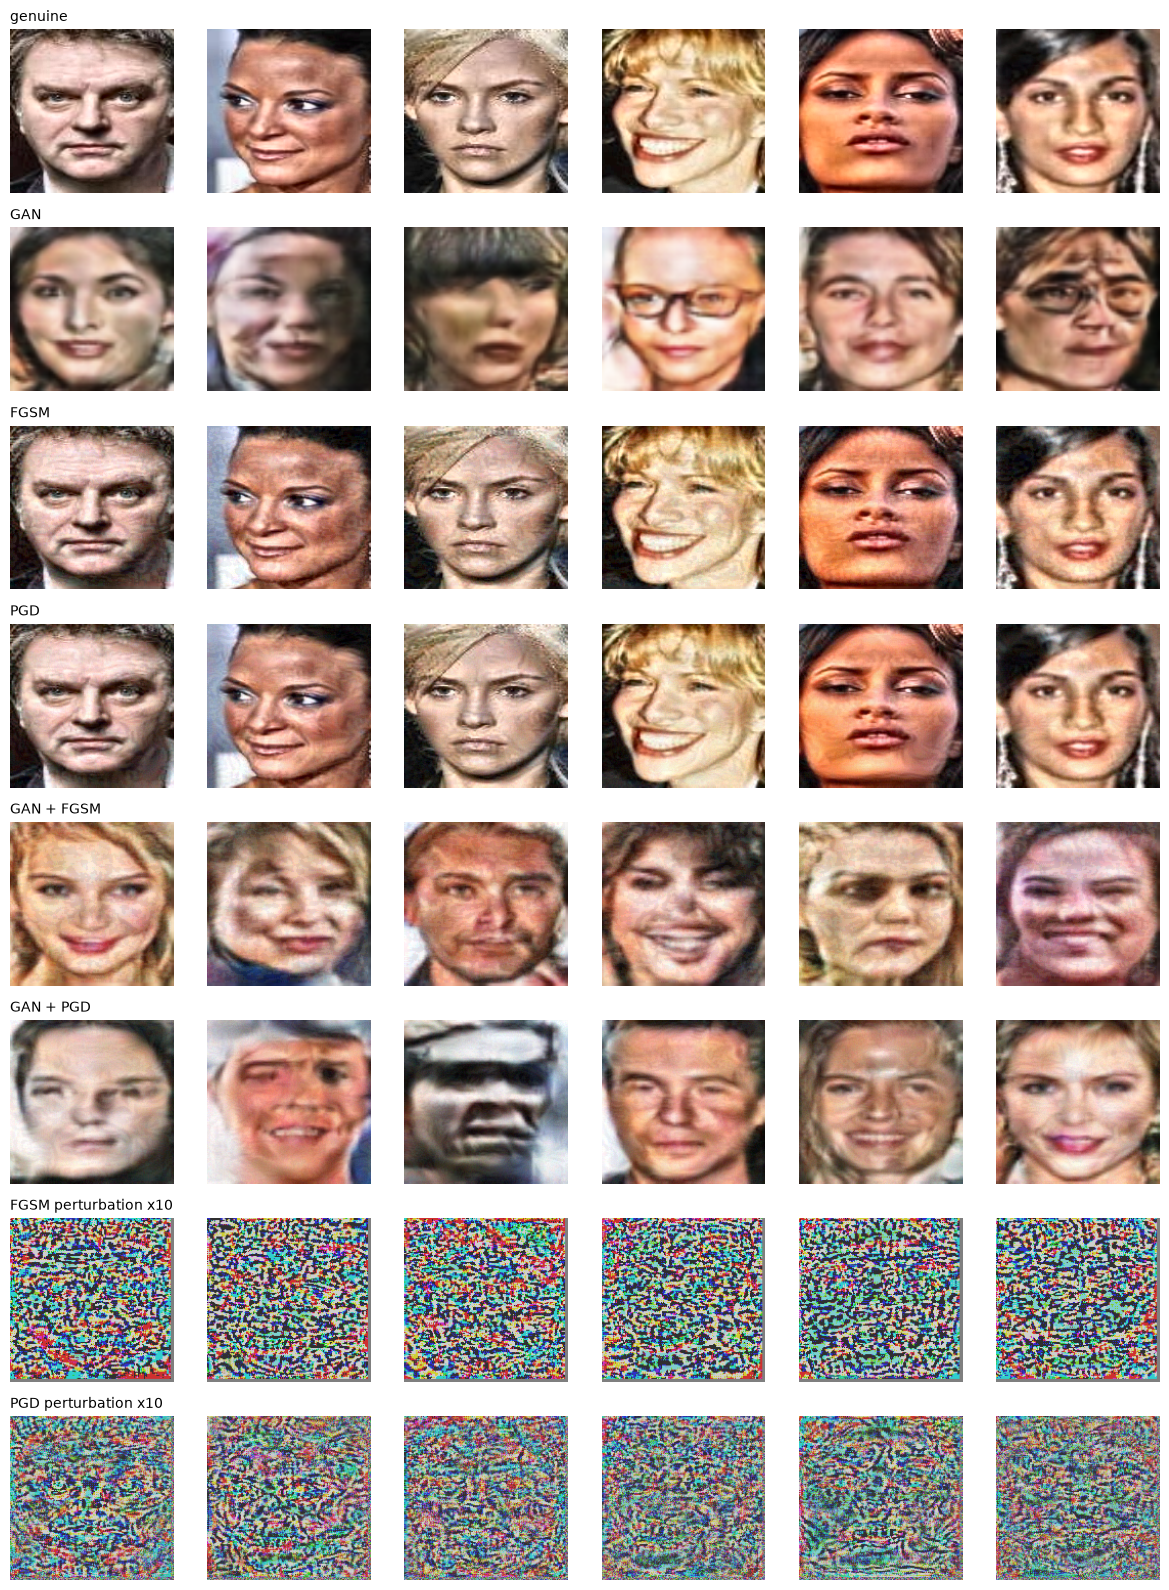

In [10]:
def show(x):
    return (x * 0.5 + 0.5).clip(0, 1).transpose(1, 2, 0)

n = 6
rows = [("genuine", x_gen), ("GAN", x_gan), ("FGSM", x_fgsm_q), ("PGD", x_pgd_q),
        ("GAN + FGSM", x_gan_fgsm_q), ("GAN + PGD", x_gan_pgd_q)]
perts = [("FGSM perturbation x10", x_fgsm_q), ("PGD perturbation x10", x_pgd_q)]

fig, axes = plt.subplots(len(rows) + len(perts), n, figsize=(2 * n, 2 * (len(rows) + len(perts))))
for r, (name, arr) in enumerate(rows):
    for c in range(n):
        axes[r, c].imshow(show(arr[c])); axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
for r, (name, arr) in enumerate(perts, start=len(rows)):
    for c in range(n):
        d = (arr[c] - x_gen[c]) * 10 * 0.5 + 0.5
        axes[r, c].imshow(d.clip(0, 1).transpose(1, 2, 0)); axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

### 7. save the dataset
PNG only. JPG compression would erase the perturbation. Output goes to `celeba/red_agent_samples/` with a `labels.csv` for the Blue Agent (Week 6).

the 5th category goes to `gan_adv/`; its file names say which attack was used (`ganadv_fgsm_000.png`, `ganadv_pgd_250.png`), and so does the new `attack` column in `labels.csv`.

In [11]:
for cat in ["genuine", "gan", "fgsm", "pgd", "gan_adv"]:
    os.makedirs(os.path.join(OUT_DIR, cat), exist_ok=True)

def save_set(cat, x, files=None, true_y=None):
    u = quantize(x).transpose(0, 2, 3, 1)            # NHWC uint8
    logits = classifier.predict(x, batch_size=BATCH)
    prob = torch.softmax(torch.from_numpy(logits), 1).numpy()
    rows = []
    for k in range(len(u)):
        name = os.path.splitext(files[k])[0] + ".png" if files else f"gan_{k:03d}.png"
        Image.fromarray(u[k]).save(os.path.join(OUT_DIR, cat, name))
        rows.append({
            "category": cat,
            "file_name": name,
            "identity": idx_to_id[int(true_y[k])] if true_y is not None else -1,
            "pred_identity": idx_to_id[int(logits[k].argmax())],
            "confidence": float(prob[k].max()),
        })
    return rows

manifest = (
    save_set("genuine", x_gen, gen_files, y_gen)
    + save_set("gan", x_gan)
    + save_set("fgsm", x_fgsm_q, gen_files, y_gen)
    + save_set("pgd", x_pgd_q, gen_files, y_gen)
)
# 5th category: combined GAN + adversarial (the file name says which attack)
u = quantize(x_gan_adv_q).transpose(0, 2, 3, 1)
logits = classifier.predict(x_gan_adv_q, batch_size=BATCH)
prob = torch.softmax(torch.from_numpy(logits), 1).numpy()
for k in range(len(u)):
    name = f"ganadv_{gan_adv_attack[k]}_{k:03d}.png"
    Image.fromarray(u[k]).save(os.path.join(OUT_DIR, "gan_adv", name))
    manifest.append({"category": "gan_adv", "file_name": name, "identity": -1,
                     "pred_identity": idx_to_id[int(logits[k].argmax())], "confidence": float(prob[k].max()),
                     "attack": gan_adv_attack[k]})

labels = pd.DataFrame(manifest)
labels["attack"] = labels["attack"].fillna(labels["category"].map({"genuine": "none", "gan": "none", "fgsm": "fgsm", "pgd": "pgd"}))
labels.to_csv(os.path.join(OUT_DIR, "labels.csv"), index=False)
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)

# so the same attack target can be rebuilt later
torch.save(head.state_dict(), os.path.join(BASE, "identity_head.pth"))
pd.Series(ids, name="identity").to_csv(os.path.join(BASE, "head_identities.csv"), index=False)

print("saved", len(manifest), "images to", OUT_DIR)
print(pd.DataFrame(manifest)["category"].value_counts().to_string())

saved 2500 images to ./celeba/red_agent_samples
category
genuine    500
gan        500
fgsm       500
pgd        500
gan_adv    500


### milestone check
- 5 categories saved, **up to 500 images each**: genuine, GAN, FGSM, PGD, and combined GAN + adversarial (`gan_adv`: 250 FGSM + 250 PGD)
- `results.csv` shows the accuracy drop under FGSM and PGD (PGD should hurt more at the same `eps`), now also for GAN faces
- `red_agent_samples.zip` (next cell) bundles everything for download
- next (Week 6): Blue Agent learns to detect the non-genuine categories from `labels.csv`

### 8. bundle for download
one zip instead of 2,000 separate files - much faster to copy to your PC with `scp`.

In [12]:
import shutil
zip_path = shutil.make_archive(os.path.join(BASE, "red_agent_samples"), "zip", OUT_DIR)
print("zip:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")
print(pd.read_csv(os.path.join(OUT_DIR, "labels.csv"))["category"].value_counts().to_string())

zip: /workspace/celeba/red_agent_samples.zip (115 MB)
category
genuine    500
gan        500
fgsm       500
pgd        500
gan_adv    500
